In [35]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

In [36]:
df = pd.read_csv('C:/Projects/data/kaggle_task/train_data.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15257 entries, 0 to 15256
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  15247 non-null  float64
 1   Name                15257 non-null  str    
 2   Year Published      15256 non-null  float64
 3   Min Players         15257 non-null  int64  
 4   Max Players         15257 non-null  int64  
 5   Play Time           15257 non-null  int64  
 6   Min Age             15257 non-null  int64  
 7   Users Rated         15257 non-null  int64  
 8   Rating Average      15257 non-null  str    
 9   BGG Rank            15257 non-null  int64  
 10  Complexity Average  15257 non-null  str    
 11  Owned Users         15240 non-null  float64
 12  Mechanics           14057 non-null  str    
 13  Domains             7608 non-null   str    
dtypes: float64(3), int64(6), str(5)
memory usage: 1.6 MB


In [37]:
df['Rating Average'] = df['Rating Average'].str.replace(',', '.').astype(float)
df['Complexity Average'] = df['Complexity Average'].str.replace(',', '.').astype(float)

df['Year Published'] = df['Year Published'].replace(0, np.nan)
year_median = df['Year Published'].median()
df['Year Published'] = df['Year Published'].fillna(year_median)

year_clipped = df['Year Published'].clip(lower=1950, upper=2021)
df['Age'] = (2021 - year_clipped).clip(lower=0)

df['Play Time'] = df['Play Time'].replace(0, np.nan)
play_median = df['Play Time'].median()
df['Play Time'] = df['Play Time'].fillna(play_median)
df['Play Time'] = df['Play Time'].clip(lower=5, upper=600)

owned_median = df['Owned Users'].median()
df['Owned Users'] = df['Owned Users'].fillna(owned_median)

df['log_rated_ratio'] = np.log1p(df['Users Rated']) / np.log1p(df['Owned Users'] + 1 )

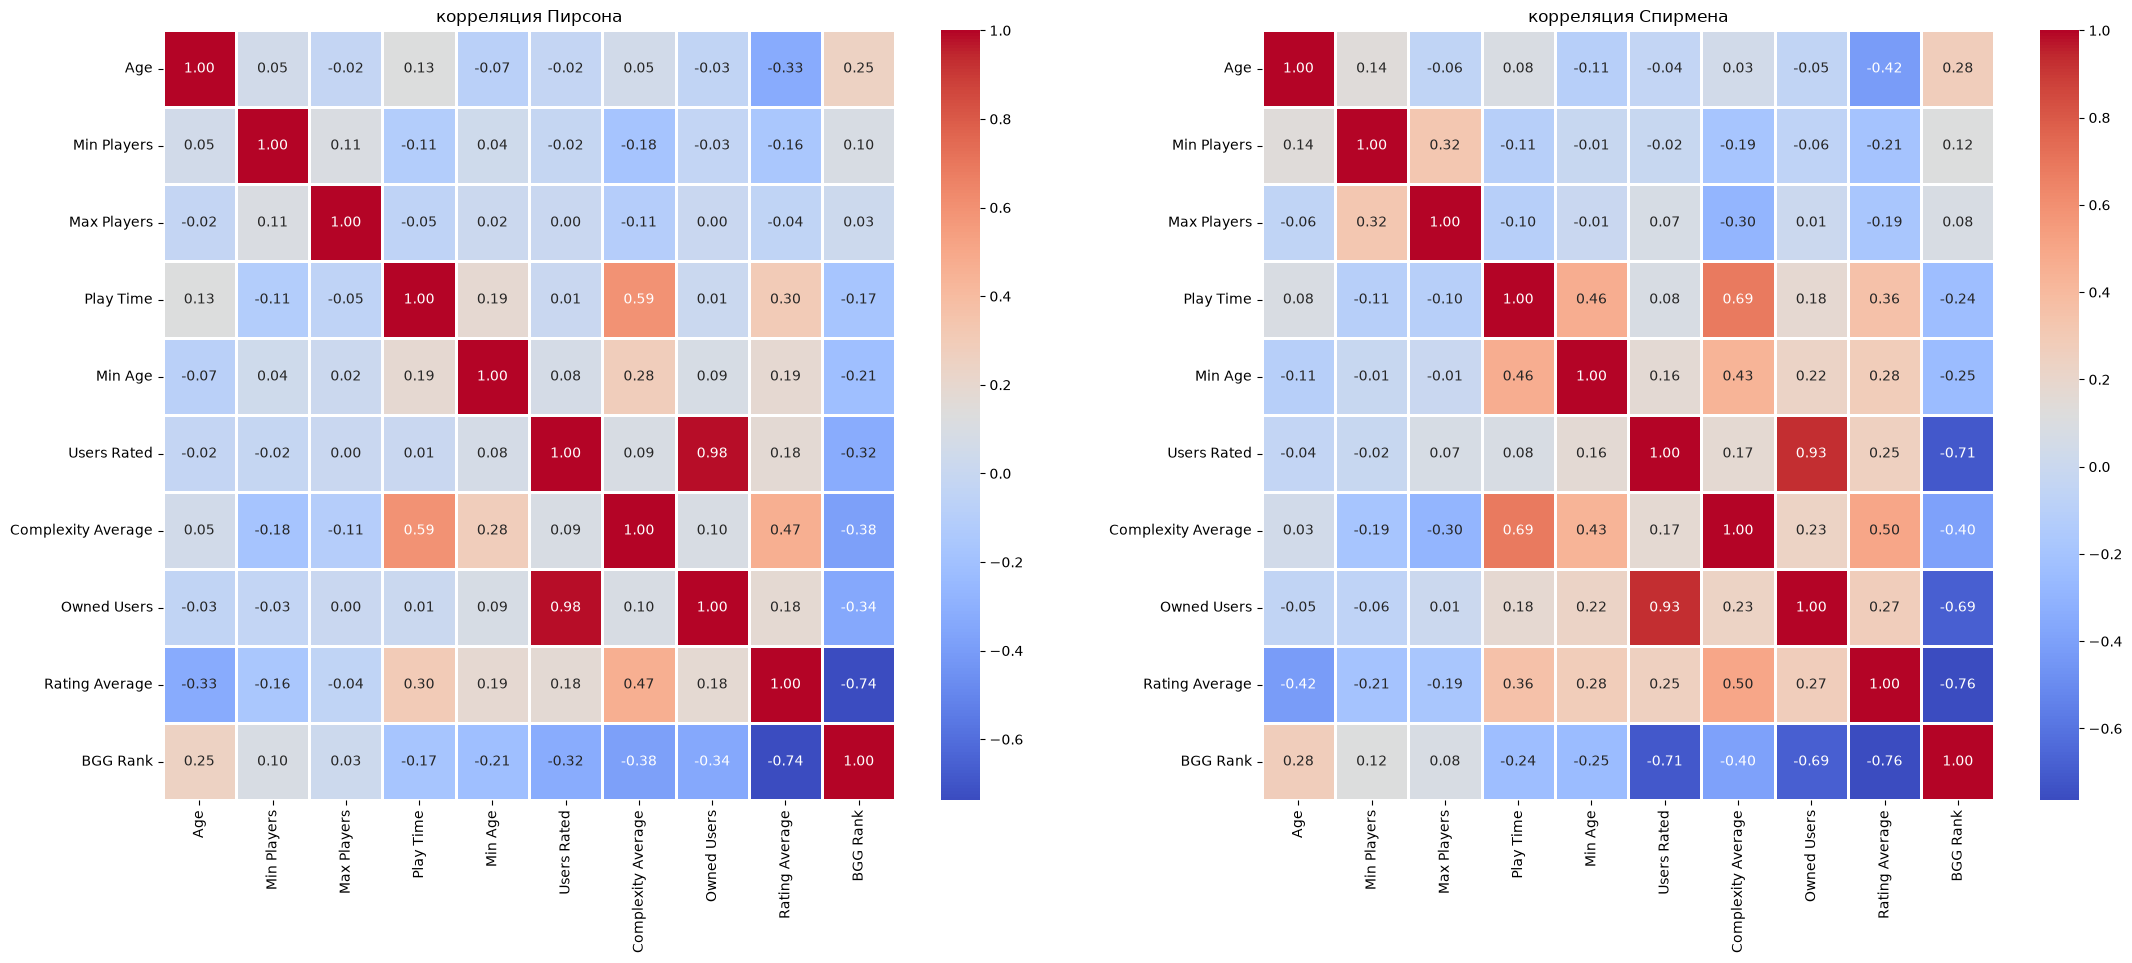

In [38]:
numeric_cols = [
    'Age', 'Min Players', 'Max Players', 'Play Time',
    'Min Age', 'Users Rated', 'Complexity Average', 'Owned Users',
    'Rating Average', 'BGG Rank'
]

fig, axes = plt.subplots(1, 2, figsize=(26, 10))
sns.heatmap(
    df[numeric_cols].corr(), 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    linecolor='white', 
    linewidths=1,
    ax=axes[0]  
)
axes[0].set_title('корреляция Пирсона')
sns.heatmap(
    df[numeric_cols].corr(method='spearman'), 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    linecolor='white', 
    linewidths=1,
    ax=axes[1]
)
axes[1].set_title('корреляция Спирмена')
plt.show()

In [39]:
df['Mechanics'] = df['Mechanics'].fillna('None')
df['Mechanics'] = df['Mechanics'].apply(lambda x: [m.strip() for m in x.split(',') if m.strip()])

df['Domains'] = df['Domains'].fillna('None')
df['Domains'] = df['Domains'].apply(lambda x: [m.strip() for m in x.split(',') if m.strip()])


mlb_mech = MultiLabelBinarizer()
mechanics_encoded = mlb_mech.fit_transform(df['Mechanics'])

mechanics_df = pd.DataFrame(
    mechanics_encoded, 
    columns=['mech_' + col for col in mlb_mech.classes_], 
    index=df.index
)
mlb_dom = MultiLabelBinarizer()
domain_encoded = mlb_dom.fit_transform(df['Domains'])

domain_df = pd.DataFrame(
    domain_encoded, 
    columns=['dom_' + col for col in mlb_dom.classes_], 
    index=df.index
)

df = pd.concat([df, mechanics_df, domain_df], axis=1)

X = df.drop(columns=[
    'Rating Average', 'ID', 'Name', 'BGG Rank',
    'Year Published', 'Mechanics', 'Domains'])

# X['comp_log_users'] = X['Complexity Average'] * np.log1p(X['Users Rated'])
# X['log_rated_ratio'] = np.log1p(X['Users Rated']) / np.log1p(X['Owned Users'] + 1 )
# X['hard_level'] = X['Complexity Average'] * np.log1p(X['Play Time'])
# X.drop(columns=['Users Rated', 'Owned Users'])

X.columns = [re.sub(r'[\[\]{}:,"]+', '_', str(col)) for col in X.columns]
X.columns = [re.sub(r'\s+', '_', str(col)) for col in X.columns]

y = df['Rating Average']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [40]:
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=16,
    min_samples_split=6,
    min_samples_leaf=3,
    max_features=0.4,
    bootstrap=True,
    max_samples=0.8,
    random_state=42,
    n_jobs=-1
)

In [41]:
gb = GradientBoostingRegressor(
n_estimators=650,
    learning_rate=0.03,
    max_depth=5,
    min_samples_split=8,
    min_samples_leaf=6,
    subsample=0.8,
    max_features=0.7,
    random_state=42
)

In [42]:
xgb = XGBRegressor(
n_estimators=1100,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.75,
    reg_alpha=0.1,
    reg_lambda=2.0,
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
    # device='cuda'
)

In [43]:
lgb = LGBMRegressor(
n_estimators=1100,
    learning_rate=0.03,
    num_leaves=28,
    min_child_samples=25,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.75,
    reg_alpha=0.2,
    reg_lambda=2.0,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

In [44]:
cb = CatBoostRegressor(
iterations=1400,
    learning_rate=0.03,
    depth=6,
    grow_policy='Depthwise',
    l2_leaf_reg=5.0,
    random_strength=0.8,
    # task_type='GPU',
    thread_count=-1,
    random_seed=42,
    verbose=0,
    allow_writing_files=False
)

In [45]:
models = {
    'Random Forest': rf,
    'Gradient Boosting': gb,
    'LightGBM': lgb,
    'XGBoost': xgb,
    'CatBoost': cb
}

models_mse = {}
kf = KFold(n_splits=10, shuffle=True, random_state=42)

In [46]:
for name, model in models.items():
    if name in ('CatBoost', 'XGBoost'):
        scores = cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error', n_jobs=-1)
        models_mse[name] = -scores.mean()
        print(f'{name}: {-scores.mean():.4f}')
    else:
        scores = cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error', n_jobs=-1)
        models_mse[name] = -scores.mean()
        print(f'{name}: {-scores.mean():.4f}')

Random Forest: 0.3740
Gradient Boosting: 0.3669
LightGBM: 0.3672
XGBoost: 0.3646
CatBoost: 0.3644


In [47]:
oof_xgb = cross_val_predict(xgb, X, y, cv=kf, n_jobs=-1)
oof_cb  = cross_val_predict(cb,  X, y, cv=kf, n_jobs=-1)
oof_lgb = cross_val_predict(lgb, X, y, cv=kf, n_jobs=-1)

oof_blend = 0.4 * oof_xgb + 0.4 * oof_cb + 0.2 * oof_lgb

print(f'mse: {mean_squared_error(y, oof_blend):.4f}')

mse: 0.3611


In [ ]:
test_df = pd.read_csv('C:/Projects/data/kaggle_task/test_data.csv')

test_df['Complexity Average'] = test_df['Complexity Average'].astype(str).str.replace(',', '.').astype(float)

test_df['Year Published'] = test_df['Year Published'].replace(0, np.nan).fillna(year_median)
year_clipped_test = test_df['Year Published'].clip(lower=1950, upper=2021)
test_df['Age'] = (2021 - year_clipped_test).clip(lower=0)

test_df['Play Time'] = test_df['Play Time'].replace(0, np.nan).fillna(play_median)
test_df['Play Time'] = test_df['Play Time'].clip(lower=5, upper=600)

test_df['Owned Users'] = test_df['Owned Users'].fillna(owned_median)
test_df['log_rated_ratio'] = np.log1p(test_df['Users Rated']) / np.log1p(test_df['Owned Users'] + 1)

test_df['Mechanics'] = test_df['Mechanics'].fillna('None')
test_df['Mechanics'] = test_df['Mechanics'].apply(lambda x: [m.strip() for m in x.split(',') if m.strip()])

test_df['Domains'] = test_df['Domains'].fillna('None')
test_df['Domains'] = test_df['Domains'].apply(lambda x: [m.strip() for m in x.split(',') if m.strip()])

mech_encoded_test = mlb_mech.transform(test_df['Mechanics'])
mechanics_df_test = pd.DataFrame(
    mech_encoded_test, 
    columns=['mech_' + col for col in mlb_mech.classes_], 
    index=test_df.index
)

dom_encoded_test = mlb_dom.transform(test_df['Domains'])
domain_df_test = pd.DataFrame(
    dom_encoded_test, 
    columns=['dom_' + col for col in mlb_dom.classes_], 
    index=test_df.index
)

test_df = pd.concat([test_df, mechanics_df_test, domain_df_test], axis=1)

X_test = test_df.drop(columns=['ID', 'Name', 'Year Published', 'Mechanics', 'Domains'])

X_test.columns = [re.sub(r'[\[\]{}:,"]+', '_', str(col)) for col in X_test.columns]
X_test.columns = [re.sub(r'\s+', '_', str(col)) for col in X_test.columns]

X_test = X_test[X.columns]

In [546]:
lgb.fit(X, y)
xgb.fit(X, y)
cb.fit(X, y)

CatBoostRegressor(allow_writing_files=False, depth=6, grow_policy='Depthwise', iterations=1400, l2_leaf_reg=5.0, learning_rate=0.03, loss_function='RMSE', random_seed=42, random_strength=0.8, task_type='GPU', verbose=0)

In [ ]:
pred_lgb = lgb.predict(X_test)
pred_xgb = xgb.predict(X_test)
pred_cb = cb.predict(X_test)

final_preds = 0.4 * pred_xgb + 0.4 * pred_cb + 0.2 * pred_lgb

submission = pd.DataFrame({'Rating Average': final_preds})
submission.index.name = 'ID'

submission.to_csv('submission.csv', index=True)